# 16 - Vision classique : seuillage, blobs, mesure en millimetres, comparaison a une reference

Sans apprentissage, et pourtant souvent suffisant quand le contraste est franc, les pieces
identiques et bien positionnees, ou quand il s'agit de MESURER. Dans tous les cas, c'est la base
de comparaison qu'un modele appris doit battre pour justifier sa complexite.

Ce que l'on apprend :
1. fabriquer une carte de reponse (les defauts ressortent) puis la seuiller : Otsu, triangle,
   adaptatif, seuil fixe ;
2. mesurer chaque tache (blob) : aire, elongation, circularite, orientation, et filtrer ;
3. mesurer en millimetres : calibration sur damier, bords au sous-pixel ;
4. comparer a une piece de reference alignee (ECC) ;
5. ecrire des regles de decision lisibles (en mm) ;
6. regler seuil et aire minimale sur la VALIDATION, lire le test une fois : Magnetic Tile
   (surface texturee) et MVTec bottle (pieces identiques).

Donnees : `python tools/get_data/get_magnetic_tile.py` et `get_mvtec_bottle.py` (MVTec AD :
CC BY-NC-SA 4.0, usage non commercial). Prerequis : socle de la toolbox pour `vtb.viz`.
Duree sur un CPU 2 coeurs : environ 2 minutes (le notebook est deja rapide : QUICK ne change rien).
Lancer depuis la racine du depot.

**Dans le fil** : ce notebook approfondit l'etape 5 (Pretraiter : carte de reponse, seuillage, blobs,
mesures) et l'etape 11 (Evaluer : seuil et aire regles sur la validation, test lu une fois). Pas de
modele appris ici : les etapes 8 a 10 sont remplacees par des regles de decision ecrites a la main.
Le fil des 13 etapes, le meme que dans le cours : `ETAPES.md`, a la racine de la toolbox.

## 0. Reglages (etape 1)

Memes valeurs que les configurations de la recette `classical` (`magnetic_tile.yaml`,
`mvtec_bottle_reference.yaml`) : memes decoupages, memes grilles, memes chiffres.

In [1]:
import itertools  # itertools : outils pour parcourir des combinaisons (ici tous les couples seuil x aire)
import time  # time : chronometre, pour mesurer la duree d'un calcul
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import cv2  # OpenCV : lecture, ecriture et traitement d'images (filtres, seuils, contours, geometrie)
import matplotlib.pyplot as plt  # matplotlib : tracer des figures (images, courbes)
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import pandas as pd  # pandas : tableaux de donnees (DataFrame) faciles a filtrer, lire et exporter
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from scipy.ndimage import gaussian_filter1d  # lissage gaussien d'un signal 1D (ici un profil d'intensite)
from sklearn.model_selection import train_test_split  # coupe un jeu de donnees en deux parties (ex. reste / test)

from vtb import viz  # module d'affichage de la toolbox : grilles d'images, superpositions, tableaux

QUICK = True  # sans effet ici : tout tourne en 2 minutes sur CPU
SEED = 42  # graine du hasard (runtime.seed de la recette) : memes tirages a chaque execution
TILE_ROOT = Path("data/raw/magnetic_tile")  # dossier Magnetic Tile : MT_<classe>/Imgs/x.jpg + masque x.png
TILE_EXTENSIONS = {".jpg"}  # seules les .jpg sont des images ; les .png a cote sont les masques
TILE_PER_CLASS = 60  # sous-echantillon par classe (max_per_class de la recette) : calcul rapide
TILE_VAL, TILE_TEST = 0.2, 0.3  # 20 % des tuiles pour la validation (regler), 30 % pour le test (juger)
TILE_THRESHOLDS = [0.04, 0.06, 0.08, 0.1, 0.12, 0.16, 0.2]  # seuils essayes, en fractions de la dynamique [0, 1]
TILE_MIN_AREAS = [50, 150, 400]  # aire minimale d'un blob (pixels) : plus petit = bruit ignore
BOTTLE_ROOT = Path("data/raw/mvtec_bottle")  # train/good, test/<type>, ground_truth/<type>/<nom>_mask.png
BOTTLE_SIZE = 256  # les bouteilles sont reduites a 256 x 256 pixels : calcul et alignement plus rapides
BOTTLE_VAL_SHARE = 0.4  # part du test MVTec gardee pour regler seuil et aire (le reste : test)
REFERENCE_IMAGES = 60  # images normales de train fusionnees en une reference (mediane)
BLUR_SIGMA = 2.0  # flou gaussien (ecart-type en pixels) avant la difference : efface bruit et residu d'alignement
BOTTLE_THRESHOLDS = [0.08, 0.12, 0.16, 0.2, 0.25, 0.3]  # seuils essayes sur la difference a la reference (dans [0, 1])
BOTTLE_MIN_AREAS = [20, 60, 150]  # aires minimales essayees pour les bouteilles (pixels)
MAX_FALSE_ALARM = 0.0  # bouteilles : meilleur rappel SANS fausse alarme sur la validation
OUT = Path("outputs/notebooks/16_vision_classique")  # dossier ou le notebook ecrit ses fichiers (decoupages, grilles)
OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier (et ses parents) ; pas d'erreur s'il existe deja
viz.setup_notebook(dpi=80, fmt="jpeg")  # figures en 80 points par pouce et en JPEG : notebook plus leger


def list_images(folder: Path, extensions: set[str]) -> list[Path]:  # renvoie la liste triee des images d'un dossier
    # rglob("*") parcourt tous les sous-dossiers ; on garde les fichiers a la bonne extension, tries (meme ordre partout)
    return sorted(p for p in Path(folder).rglob("*") if p.is_file() and p.suffix.lower() in extensions)


def read_gray(path: str | Path) -> np.ndarray:  # lit une image et la renvoie en niveaux de gris (tableau 2D)
    """Lecture robuste (chemins avec accents) ; une image couleur est convertie en gris par OpenCV."""
    # np.fromfile lit les octets bruts (accepte les accents), imdecode les decode ; UNCHANGED : 8 ou 16 bits garde
    image = cv2.imdecode(np.fromfile(str(path), np.uint8), cv2.IMREAD_UNCHANGED)
    if image is None:  # None = le fichier n'est pas une image lisible
        raise ValueError(f"image illisible : {path}")  # on arrete tout de suite avec un message clair
    # couleur (3 dimensions) -> gris ; [..., :3] retire un eventuel canal alpha (transparence) ; deja grise : inchangee
    return cv2.cvtColor(image[..., :3], cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image


def read_mask(path: str) -> np.ndarray:  # lit un masque de verite (pixels du defaut) et le renvoie en 0 / 1
    """Masque binaire {0, 1} ; le seuil a 127 ignore les bords anti-creneles des PNG."""
    return (read_gray(path) > 127).astype(np.uint8)  # pixel > 127 -> 1 (defaut), sinon 0 ; uint8 = entier de 0 a 255


def as_float(image: np.ndarray) -> np.ndarray:  # convertit une image entiere en flottants dans [0, 1]
    return image.astype(np.float32) / (255.0 if image.dtype == np.uint8 else 65535.0)  # 255 en 8 bits, 65535 en 16 bits

## 1. Une carte de reponse, puis un seuil (etape 5)

Sur une tuile magnetique, les defauts (trous, fissures) sont plus SOMBRES que le fond, mais
l'eclairage varie et la texture a du grain. Trois operations font ressortir les defauts :
- filtre median 7 : efface le grain sans emousser les bords ;
- division par le fond flou (sigma 30) : corrige l'eclairage (calcul sur l'image reduite de
  moitie, 4 fois plus rapide pour un fond lisse) ;
- black-hat 21 (fermeture - image) : ne garde que les petits objets sombres, rendus en CLAIR.

Puis quatre facons de seuiller. Otsu et triangle choisissent le seuil image par image : pratique,
mais le seuil n'est alors plus le meme d'une image a l'autre ; en production on prefere un seuil
FIXE regle sur la validation (section 6).

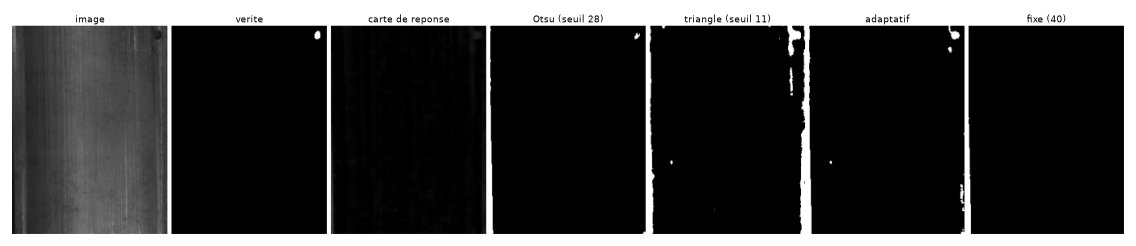

In [2]:
def median_blur(image: np.ndarray, ksize: int = 7) -> np.ndarray:  # filtre median : efface le grain, garde les bords
    return cv2.medianBlur(image, ksize)  # chaque pixel devient la mediane de sa fenetre ksize x ksize (ksize impair)


def shading_division(image: np.ndarray, sigma: float = 30.0, downscale: int = 2) -> np.ndarray:  # corrige l'eclairage
    """I / fond flou, ramene a la luminosite moyenne d'origine (eclairage multiplicatif)."""
    x = as_float(image)  # flottants dans [0, 1] : on peut diviser sans perte d'arrondi
    h, w = x.shape  # hauteur et largeur de l'image (pixels)
    # image reduite (INTER_AREA = moyenne des pixels regroupes) : le fond est lisse, le calculer en petit suffit
    small = cv2.resize(x, (max(1, w // downscale), max(1, h // downscale)), interpolation=cv2.INTER_AREA) if downscale > 1 else x
    # flou gaussien tres fort = estimation du fond (l'eclairage) ; sigma divise d'autant que l'image a ete reduite
    blurred = cv2.GaussianBlur(small, (0, 0), sigmaX=max(sigma / downscale, 0.5), borderType=cv2.BORDER_REFLECT)
    background = cv2.resize(blurred, (w, h), interpolation=cv2.INTER_LINEAR) if downscale > 1 else blurred  # fond a taille d'origine
    corrected = x / np.maximum(background, 1e-6) * float(background.mean())  # image / fond x luminosite moyenne ; 1e-6 : pas de / 0
    return (np.clip(corrected, 0, 1) * 255 + 0.5).astype(np.uint8)  # retour en 0-255 : clip borne, + 0.5 arrondit au plus proche


def blackhat(image: np.ndarray, kernel: int = 21) -> np.ndarray:  # black-hat : fait ressortir en CLAIR les petits objets sombres
    element = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel, kernel))  # element structurant : disque de kernel pixels
    # fermeture (bouche les creux sombres plus petits que le disque) - image = ce qui a ete bouche, donc les petits defauts
    return cv2.morphologyEx(image, cv2.MORPH_BLACKHAT, element, borderType=cv2.BORDER_REFLECT)


def tile_response(image: np.ndarray) -> np.ndarray:  # chaine complete : tuile -> carte de reponse (defauts en clair)
    return blackhat(shading_division(median_blur(image, 7), 30, 2), 21)  # median 7, puis eclairage corrige, puis black-hat 21


tile_path = list_images(TILE_ROOT / "MT_Blowhole" / "Imgs", TILE_EXTENSIONS)[3]  # 4e image de la classe Blowhole (trous)
tile = read_gray(tile_path)  # l'image de la tuile, en niveaux de gris
truth = read_mask(str(tile_path.with_suffix(".png")))  # masque de verite : meme nom de fichier, extension .png
response = tile_response(tile)  # carte de reponse : plus un pixel est clair, plus il ressemble a un defaut
# Otsu : seuil choisi automatiquement pour separer au mieux deux populations de pixels (fond / objets) ; pixel > seuil -> 1
otsu_value, otsu = cv2.threshold(response, 0, 1, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
# triangle : autre seuil automatique, adapte quand le fond domine largement l'histogramme des niveaux de gris
triangle_value, triangle = cv2.threshold(response, 0, 1, cv2.THRESH_BINARY | cv2.THRESH_TRIANGLE)
# adaptatif : un seuil par pixel = moyenne de sa fenetre 51 x 51 + 10 (le -10 est soustrait du seuil, donc + 10)
adaptive = cv2.adaptiveThreshold(response, 1, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 51, -10)  # seuil = moyenne locale + 10
_, fixed = cv2.threshold(response, 40, 1, cv2.THRESH_BINARY)  # seuil fixe a 40 : pixel > 40 -> 1 ; _ ignore le seuil renvoye
viz.grid(  # affiche les images cote a cote dans une grille, avec un titre chacune
    [tile, truth * 255, response, otsu * 255, triangle * 255, adaptive * 255, fixed * 255],  # masques 0/1 x 255 : visibles en blanc
    [  # les titres, dans le meme ordre que les images
        "image",  # la tuile d'origine
        "verite",  # le masque du defaut, dessine a la main
        "carte de reponse",  # la carte avant seuillage
        f"Otsu (seuil {otsu_value:.0f})",  # :.0f = valeur arrondie, sans decimale
        f"triangle (seuil {triangle_value:.0f})",  # seuil trouve par la methode triangle
        "adaptatif",  # seuil local
        "fixe (40)",  # seuil fixe
    ],
    ncols=7,  # 7 colonnes : toutes les images sur une ligne
    size=2.0,  # taille de chaque vignette (pouces)
)

## 2. Analyse de blobs : distinguer une piqure d'une rayure par la forme (etape 5)

Apres un seuillage, chaque tache (composante connexe) est mesuree :
- aire, boite, centre ;
- circularite = 4 pi aire / perimetre^2 (1 pour un disque, proche de 0 pour une ligne) ;
- elongation = rapport des axes de l'ellipse d'inertie (moments centres d'ordre 2) : 1 pour un
  disque, grand pour une rayure ; angle de l'axe principal ;
- intensite moyenne et maximale sur l'image (ou la carte).
Le tableau pandas se filtre, se lit et s'exporte directement.

,id,x,y,width,height,area,cx,cy,circularity,elongation,angle,mean_intensity,max_intensity
0,1,89,19,43,53,217,110.0,45.0,0.14,20.22,51.37,220.0,220.0
1,2,168,28,25,25,441,180.0,40.0,0.93,1.00,0.00,220.0,220.0
2,3,31,31,19,19,253,40.0,40.0,0.95,1.00,0.00,220.0,220.0
3,4,115,95,11,11,81,120.0,100.0,0.94,1.00,0.00,220.0,220.0
4,5,19,109,183,18,530,110.0,117.5,0.05,62.90,4.77,220.0,220.0


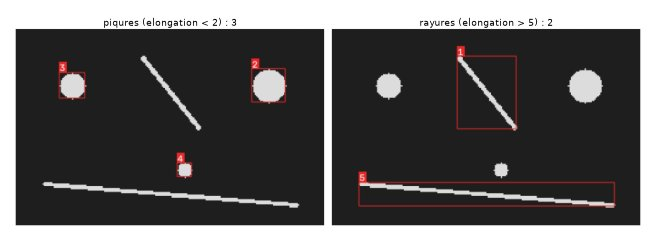

In [3]:
# mesure chaque tache (blob) d'un masque ; renvoie un tableau pandas, une ligne par blob
def blob_table(mask: np.ndarray, image: np.ndarray | None = None) -> pd.DataFrame:
    # composantes connexes : groupes de pixels allumes qui se touchent (8 voisins) ; labels = numero du blob de chaque pixel
    count, labels, stats, centroids = cv2.connectedComponentsWithStats((mask > 0).astype(np.uint8), connectivity=8)
    values_image = None if image is None else image.astype(np.float32)  # intensites en flottants (None si pas d'image)
    rows = []  # une ligne (dict) par blob, transformee en tableau a la fin
    for k in range(1, count):  # pour chaque blob ; le numero 0 est le fond, on commence a 1
        x, y, w, h, area = (int(v) for v in stats[k])  # boite englobante (coin, largeur, hauteur) et aire en pixels
        component = (labels[y : y + h, x : x + w] == k).astype(np.uint8)  # masque 0/1 du blob k, decoupe dans sa boite
        contours, _ = cv2.findContours(component, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)  # contour exterieur, tous les points
        perimeter = float(sum(cv2.arcLength(c, True) for c in contours))  # perimetre = longueur du contour ferme (True)
        m = cv2.moments(component, binaryImage=True)  # moments : sommes ponderees des positions des pixels (centre, inertie)
        common = np.sqrt(4 * m["mu11"] ** 2 + (m["mu20"] - m["mu02"]) ** 2)  # terme commun aux deux axes de l'ellipse d'inertie
        major, minor = (m["mu20"] + m["mu02"] + common) / 2, (m["mu20"] + m["mu02"] - common) / 2  # inertie grand axe, petit axe
        # intensites des pixels du blob (dans sa boite, la ou component vaut 1) ; NaN s'il n'y a pas d'image
        values = values_image[y : y + h, x : x + w][component > 0] if values_image is not None else np.array([np.nan])
        rows.append(  # ajoute la ligne de mesures de ce blob
            {  # dictionnaire : nom de colonne -> valeur
                "id": k,  # numero du blob
                "x": x,  # colonne du coin haut-gauche de la boite
                "y": y,  # ligne du coin haut-gauche de la boite
                "width": w,  # largeur de la boite (pixels)
                "height": h,  # hauteur de la boite (pixels)
                "area": area,  # aire : nombre de pixels du blob
                "cx": float(centroids[k][0]),  # centre de gravite, coordonnee x
                "cy": float(centroids[k][1]),  # centre de gravite, coordonnee y
                "circularity": float(4 * np.pi * area / perimeter**2) if perimeter > 0 else 1.0,  # 1 = disque, ~0 = ligne
                "elongation": float(np.sqrt(major / minor)) if minor > 1e-9 else float(max(w, h)),  # 1 = disque, grand = rayure
                "angle": float(np.degrees(0.5 * np.arctan2(2 * m["mu11"], m["mu20"] - m["mu02"]))),  # orientation du grand axe (degres)
                "mean_intensity": float(values.mean()),  # intensite moyenne dans le blob
                "max_intensity": float(values.max()),  # intensite maximale dans le blob
            }
        )
    return pd.DataFrame(rows)  # la liste de dicts devient un tableau pandas (une ligne par blob)


def draw_blobs(image: np.ndarray, table: pd.DataFrame, color=(230, 40, 40)) -> np.ndarray:  # encadre chaque blob, avec son numero
    boxes = table[["x", "y", "width", "height"]].to_numpy(float).copy()  # boites en tableau numpy ; copy() : le tableau reste intact
    boxes[:, 2:] += boxes[:, :2] - 1  # largeur / hauteur -> coin bas-droit (x2 = x + w - 1) : format xyxy attendu
    # dessine les boites ; min_side=300 agrandit d'abord les petites images pour que les numeros restent lisibles
    return viz.draw_boxes(image, boxes, labels=table["id"].astype(str).tolist(), color=color, min_side=300)


shapes = np.full((140, 220), 30, np.uint8)  # image de test synthetique : 140 x 220 pixels, fond gris sombre (30)
for center, radius in (((40, 40), 9), ((120, 100), 5), ((180, 40), 12)):  # trois disques : (centre x, y), rayon
    cv2.circle(shapes, center, radius, 220, -1)  # dessine un disque clair (220) ; -1 = rempli
cv2.line(shapes, (20, 110), (200, 125), 220, 2)  # une rayure : ligne claire de 2 pixels d'epaisseur
cv2.line(shapes, (90, 20), (130, 70), 220, 2)  # une seconde rayure, en biais
table = blob_table(shapes > 128, shapes)  # masque = pixels clairs ; mesure des blobs avec leurs intensites
display(table.round(2))  # affiche le tableau, arrondi a 2 decimales
pits, scratches = table[table["elongation"] < 2], table[table["elongation"] > 5]  # tri par forme : peu allonge / tres allonge
viz.grid(  # affiche les deux familles cote a cote
    [draw_blobs(shapes, pits), draw_blobs(shapes, scratches)],  # l'image avec les piqures encadrees, puis avec les rayures
    [f"piqures (elongation < 2) : {len(pits)}", f"rayures (elongation > 5) : {len(scratches)}"],  # titres avec le nombre de blobs
    ncols=2,  # deux colonnes
    size=4,  # vignettes plus grandes (pouces)
    max_side=440,  # cote maximal affiche (pixels) : garde le detail des boites
)

## 3. Mesurer en millimetres (etape 5)

Une mesure fiable demande trois choses, dans cet ordre :
1. une optique corrigee (calibration de camera : `calibrateCamera` sur une dizaine de vues d'un
   damier, puis `undistort`) ; sans elle, les bords de l'image mesurent faux ;
2. une echelle connue (mm par pixel) ;
3. une localisation des bords plus fine que le pixel : maximum de la derivee du profil lisse,
   affine par une parabole passant par les trois points autour du maximum.

Tout est synthetique ici (pas de camera) : un damier de cases de 5 mm (20 pixels) vu sous huit
angles, puis une bande de 60,25 mm mesuree ligne par ligne.

calibration : 8 vues, erreur de reprojection 0.66 px, echelle 0.2500 mm / px (vraie : 0.2500)
largeur mesuree : 60.255 mm +/- 0.032 (ecart-type sur 60 lignes) ; vraie largeur 60.25 mm


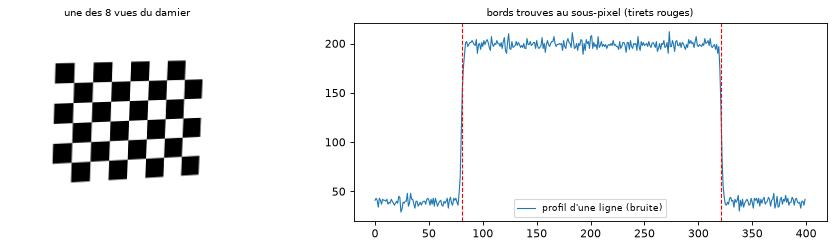

In [4]:
SQUARE_PX, SQUARE_MM, PATTERN = 20, 5.0, (7, 5)  # case = 20 px = 5 mm ; PATTERN : coins INTERIEURS (colonnes, lignes)


def chessboard_views(n_views: int = 8, seed: int = 0) -> list[np.ndarray]:  # renvoie n_views images d'un damier vu de biais
    rows, cols = PATTERN[1] + 1, PATTERN[0] + 1  # nombre de cases : une de plus que de coins interieurs dans chaque sens
    board = np.full(((rows + 2) * SQUARE_PX, (cols + 2) * SQUARE_PX), 255, np.uint8)  # image blanche, marge d'une case autour
    for r in range(rows):  # pour chaque rangee de cases
        for c in range(cols):  # pour chaque colonne de cases
            if (r + c) % 2 == 0:  # une case sur deux (alternance noir / blanc)
                # peint la case en noir ; le + 1 decale d'une case pour laisser la marge blanche
                board[(r + 1) * SQUARE_PX : (r + 2) * SQUARE_PX, (c + 1) * SQUARE_PX : (c + 2) * SQUARE_PX] = 0
    h, w = board.shape  # hauteur et largeur du damier (pixels)
    rng, views = np.random.default_rng(seed), []  # generateur aleatoire reproductible, et liste des vues
    src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])  # les 4 coins de l'image d'origine
    for k in range(n_views):  # pour chaque vue a fabriquer
        # deplacement aleatoire des 4 coins (+/- 12 px) ; la premiere vue (k = 0) reste droite (jitter nul)
        jitter = rng.uniform(-12, 12, (4, 2)).astype(np.float32) if k else np.zeros((4, 2), np.float32)
        # perspective : les 4 coins vont a leur place deplacee (+ 20 px de marge) ; fond blanc (255) autour
        views.append(cv2.warpPerspective(board, cv2.getPerspectiveTransform(src, src + jitter + 20), (w + 40, h + 40), borderValue=255))
    return views  # la liste des images du damier


# calibre la camera sur des vues de damier ; renvoie un dict : vues utilisees, erreur, echelle mm / pixel, optique
def calibrate_chessboard(images: list[np.ndarray], pattern: tuple[int, int], square_mm: float) -> dict:
    template = np.zeros((pattern[0] * pattern[1], 3), np.float32)  # positions REELLES des coins (x, y, z = 0 : damier plat)
    template[:, :2] = np.mgrid[0 : pattern[0], 0 : pattern[1]].T.reshape(-1, 2) * square_mm  # grille des coins, en millimetres
    object_points, image_points = [], []  # coins en mm (reels) et coins trouves dans les images (pixels), vue par vue
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1e-3)  # arret de l'affinage : 30 iterations ou 1e-3 px
    for gray in images:  # pour chaque vue du damier
        found, corners = cv2.findChessboardCorners(gray, pattern, None)  # cherche les coins interieurs ; found = tous trouves
        if found:  # on ne garde que les vues ou le damier entier est detecte
            object_points.append(template)  # les coins reels (les memes pour chaque vue)
            image_points.append(cv2.cornerSubPix(gray, corners, (5, 5), (-1, -1), criteria))  # coins affines au sous-pixel
    # estime l'optique : matrice de la camera (focales, centre) et distorsion ; rms = erreur moyenne en pixels
    rms, matrix, coeffs, _, _ = cv2.calibrateCamera(object_points, image_points, images[0].shape[::-1], None, None)
    first = image_points[0].reshape(pattern[1], pattern[0], 2)  # coins de la 1re vue (droite), ranges en lignes x colonnes
    step_px = float(np.mean(np.linalg.norm(np.diff(first, axis=1), axis=-1)))  # pas moyen entre deux coins voisins (pixels)
    return {  # resume de la calibration
        "vues": len(image_points),  # nombre de vues utilisees
        "rms_px": float(rms),  # erreur de reprojection (pixels) : petite = bonne calibration
        "mm_per_pixel": square_mm / step_px,  # echelle : taille reelle d'une case / sa taille en pixels
        "camera_matrix": matrix,  # matrice de la camera (focales et centre optique)
        "dist_coeffs": coeffs.ravel(),  # coefficients de distorsion de l'objectif, mis a plat (1D)
    }


def strongest_edge(profile: np.ndarray, direction: str = "any", sigma: float = 1.0) -> float:  # renvoie la position du bord
    """Position sous-pixel du bord le plus net : maximum de la derivee, affine par une parabole."""
    values = gaussian_filter1d(np.asarray(profile, np.float64), sigma)  # lisse le profil : le bruit ne cree pas de faux bords
    gradient = np.gradient(values)  # derivee : grande la ou l'intensite change vite (un bord)
    # rising : bord sombre -> clair ; falling : clair -> sombre (derivee negative) ; any : les deux (valeur absolue)
    score = gradient if direction == "rising" else -gradient if direction == "falling" else np.abs(gradient)
    i = int(np.argmax(score))  # indice du pixel ou le bord est le plus net
    if 0 < i < len(score) - 1:  # il faut un voisin de chaque cote pour tracer la parabole
        left, center, right = score[i - 1], score[i], score[i + 1]  # le score au maximum et a ses deux voisins
        denominator = left - 2 * center + right  # courbure de la parabole qui passe par ces 3 points
        if abs(denominator) > 1e-12:  # parabole non plate : son sommet est bien defini
            return float(i + 0.5 * (left - right) / denominator)  # sommet de la parabole = position du bord, au sous-pixel
    return float(i)  # repli : la position entiere du maximum


def strip_width(image: np.ndarray) -> pd.DataFrame:  # mesure la largeur d'une bande claire, ligne par ligne
    """Bande claire sur fond sombre : bord montant a gauche, descendant a droite, largeur en pixels, ligne par ligne."""
    half = image.shape[1] // 2  # milieu de l'image : bord gauche dans la moitie gauche, bord droit dans la droite
    rows = []  # une ligne de resultat par ligne d'image
    for y, line in enumerate(image.astype(np.float64)):  # pour chaque ligne de l'image (y = son numero)
        left = strongest_edge(line[:half], "rising")  # bord gauche : passage sombre -> clair
        right = half + strongest_edge(line[half:], "falling")  # bord droit : clair -> sombre ; + half : colonne dans l'image entiere
        rows.append({"row": y, "left": left, "right": right, "width": right - left})  # positions des bords et largeur (pixels)
    return pd.DataFrame(rows)  # tableau : une ligne par ligne d'image


views = chessboard_views()  # les 8 vues synthetiques du damier
calibration = calibrate_chessboard(views, PATTERN, SQUARE_MM)  # calibration : en sortie, l'echelle en mm par pixel
print(  # affiche le resultat de la calibration (et la vraie echelle pour comparer)
    f"calibration : {calibration['vues']} vues, erreur de reprojection {calibration['rms_px']:.2f} px, echelle {calibration['mm_per_pixel']:.4f} mm / px (vraie : {SQUARE_MM / SQUARE_PX:.4f})"
)

true_mm, scale = 60.25, calibration["mm_per_pixel"]  # vraie largeur de la bande (mm) et echelle mesuree (mm / pixel)
columns = np.arange(400, dtype=np.float64)  # positions des colonnes 0 a 399 : un profil de 400 pixels
left_edge, right_edge = 80.3, 80.3 + true_mm / (SQUARE_MM / SQUARE_PX)  # vrais bords (pixels, non entiers expres)
# bande claire (200) sur fond sombre (40) : deux sigmoides = deux bords flous, comme ceux d'une vraie optique
band = 40 + 160 / (1 + np.exp(-(columns - left_edge) / 0.8)) - 160 / (1 + np.exp(-(columns - right_edge) / 0.8))  # bords flous (optique)
# 60 lignes identiques + bruit gaussien (ecart-type 4), bornees a 0-255 : l'image a mesurer
strip = np.clip(np.tile(band, (60, 1)) + np.random.default_rng(1).normal(0, 4, (60, 400)), 0, 255).astype(np.uint8)
widths = strip_width(strip)  # largeur mesuree sur chaque ligne (pixels)
widths["width_mm"] = widths["width"] * scale  # conversion en millimetres avec l'echelle de la calibration
print(  # affiche la largeur moyenne mesuree, sa dispersion, et la vraie largeur
    f"largeur mesuree : {widths['width_mm'].mean():.3f} mm +/- {widths['width_mm'].std():.3f} (ecart-type sur {len(widths)} lignes) ; vraie largeur {true_mm} mm"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))  # une figure avec 2 graphiques cote a cote (taille en pouces)
axes[0].imshow(views[3], cmap="gray")  # a gauche : une des vues du damier, en niveaux de gris
axes[0].set_title("une des 8 vues du damier", fontsize=9)  # titre du graphique de gauche
axes[0].axis("off")  # pas d'axes gradues autour d'une image
axes[1].plot(strip[0], lw=1, label="profil d'une ligne (bruite)")  # a droite : profil d'intensite de la 1re ligne
for edge in (widths["left"].mean(), widths["right"].mean()):  # pour chacun des deux bords (position moyenne sur les lignes)
    axes[1].axvline(edge, color="red", ls="--", lw=1)  # trait vertical rouge en tirets a la position du bord
axes[1].set_title("bords trouves au sous-pixel (tirets rouges)", fontsize=9)  # titre du graphique de droite
axes[1].legend(fontsize=8)  # affiche la legende (le label du profil)
plt.tight_layout()  # ajuste les marges pour que rien ne se chevauche
plt.show()  # affiche la figure

## 4. Comparaison a une piece de reference (MVTec bottle)

La methode reine quand les pieces sont identiques et bien positionnees (circuit imprime,
etiquette, piece usinee, bouteille vue de dessus) : tout ecart significatif a la reference est un
defaut. Elle echoue des que la piece varie naturellement (textures, coulee, laminage) : c'est la
que les methodes apprises (anomalies, notebooks 13 a 15) prennent le relais.
- Reference : MEDIANE pixel a pixel de 60 images normales de train (la mediane ignore un defaut
  present sur une seule image) ;
- alignement ECC (rotation + translation) : un decalage d'un pixel ferait apparaitre de faux
  defauts sur tous les bords ;
- |image alignee - reference| apres un flou leger (absorbe le bruit et le residu d'alignement).

reference : mediane de 60 images normales en 0.9 s


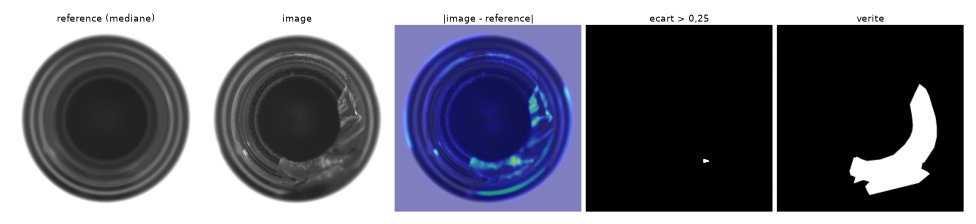

In [5]:
def resize_to(image: np.ndarray, size: int) -> np.ndarray:  # redimensionne une image en carre size x size
    """INTER_AREA pour reduire (pas de moirage), INTER_LINEAR pour agrandir."""
    flag = cv2.INTER_AREA if size * size < image.shape[0] * image.shape[1] else cv2.INTER_LINEAR  # moins de pixels -> AREA
    return cv2.resize(image, (size, size), interpolation=flag)  # redimensionne avec l'interpolation choisie


def align_ecc(image: np.ndarray, reference: np.ndarray) -> np.ndarray:  # recale l'image sur la reference et la renvoie
    """Superpose image sur reference (mouvement euclidien), convention WARP_INVERSE_MAP d'OpenCV."""
    matrix = np.eye(2, 3, dtype=np.float32)  # transformation de depart : identite (aucun deplacement), matrice 2 x 3
    criteria = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 100, 1e-5)  # arret : 100 iterations ou progres < 1e-5
    # ECC : cherche la rotation + translation qui rend les deux images le plus ressemblantes ; 5 = flou interne (robustesse)
    _, matrix = cv2.findTransformECC(as_float(reference), as_float(image), matrix, cv2.MOTION_EUCLIDEAN, criteria, None, 5)
    flags = cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP  # interpolation lineaire ; la matrice trouvee s'applique en sens inverse
    # applique la transformation ; BORDER_REPLICATE recopie le bord (pas de bande noire qui passerait pour un defaut)
    return cv2.warpAffine(image, matrix, reference.shape[::-1], flags=flags, borderMode=cv2.BORDER_REPLICATE)


# carte |image alignee - reference| dans [0, 1] : grande la ou la piece differe de la reference
def difference_map(image: np.ndarray, reference: np.ndarray, blur_sigma: float = BLUR_SIGMA) -> np.ndarray:
    a, b = as_float(align_ecc(image, reference)), as_float(reference)  # image alignee et reference, en flottants [0, 1]
    if blur_sigma > 0:  # si un flou est demande
        a, b = cv2.GaussianBlur(a, (0, 0), blur_sigma), cv2.GaussianBlur(b, (0, 0), blur_sigma)  # meme flou sur les deux images
    return np.abs(a - b)  # ecart absolu pixel par pixel (0 = identique)


bottles = []  # catalogue des images de bouteilles : une ligne (dict) par image
for p in list_images(BOTTLE_ROOT / "train" / "good", {".png"}):  # pour chaque image normale du dossier train/good
    bottles.append({"path": str(p), "label": "good", "defect_type": "good", "split": "train", "mask_path": ""})  # saine, sans masque
for type_dir in sorted(d for d in (BOTTLE_ROOT / "test").iterdir() if d.is_dir()):  # pour chaque sous-dossier de test (un type)
    for p in list_images(type_dir, {".png"}):  # pour chaque image de ce type
        mask = BOTTLE_ROOT / "ground_truth" / type_dir.name / f"{p.stem}_mask.png"  # son masque (absent pour les saines)
        label = "good" if type_dir.name == "good" else "defect"  # etiquette binaire : saine ou defectueuse
        bottles.append(  # ajoute la ligne de cette image de test
            # chemin, etiquette, type de defaut, split test, chemin du masque ("" s'il n'existe pas)
            {"path": str(p), "label": label, "defect_type": type_dir.name, "split": "test", "mask_path": str(mask) if mask.exists() else ""}
        )
bottles = pd.DataFrame(bottles)  # la liste de dicts devient un tableau pandas
start = time.perf_counter()  # demarre le chronometre
pool = bottles[(bottles["split"] == "train") & (bottles["label"] == "good")].head(REFERENCE_IMAGES)  # 60 images saines de train
stack = np.stack([resize_to(read_gray(p), BOTTLE_SIZE) for p in pool["path"]])  # empile : tableau (images, hauteur, largeur)
reference = np.median(stack, axis=0).astype(stack.dtype)  # mediane pixel a pixel : la bouteille "type", sans defaut isole
print(f"reference : mediane de {len(pool)} images normales en {time.perf_counter() - start:.1f} s")  # nombre d'images et duree

example = bottles[bottles["defect_type"] == "broken_large"].iloc[0]  # premiere bouteille du type "grosse casse"
image = resize_to(read_gray(example["path"]), BOTTLE_SIZE)  # son image en gris, reduite a 256 x 256
diff = difference_map(image, reference)  # ecart a la reference apres alignement
example_mask = (diff > 0.25).astype(np.uint8)  # seuil a 0,25 : pixels nettement differents -> 1
viz.grid(  # affiche reference, image, ecart, masque obtenu et verite
    # carte de chaleur de l'ecart (echelle 0 a 0,5) superposee a l'image ; masques 0/1 x 255 pour les voir en blanc
    [reference, image, viz.overlay_heatmap(image, diff, vmin=0, vmax=0.5), example_mask * 255, read_mask(example["mask_path"]) * 255],
    ["reference (mediane)", "image", "|image - reference|", "ecart > 0,25", "verite"],  # titres, dans le meme ordre
    ncols=5,  # 5 colonnes : tout sur une ligne
    size=2.4,  # taille de chaque vignette (pouces)
)

## 5. Des regles de decision lisibles (a la place des etapes 8 a 10)

La force de la vision classique en production : une decision qu'on EXPLIQUE au controle qualite.
Les blobs sont convertis en millimetres (echelle de la calibration ; ici 0,1 mm / pixel suppose
pour les tuiles) et compares a des tolerances ecrites dans la specification du produit.

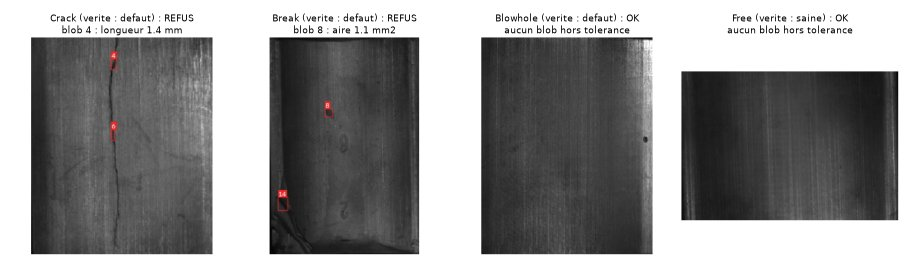

In [6]:
MM_PER_PIXEL_TILE = 0.1  # echelle supposee des tuiles : 1 pixel = 0,1 mm (viendrait d'une calibration)
RULES = {"aire_mm2": 1.0, "longueur_mm": 1.2}  # tolerances (exemple) : au-dela, la piece est refusee


# applique les regles a chaque blob ; renvoie ("OK" ou "REFUS", liste des raisons du refus)
def decide(table: pd.DataFrame, mm_per_pixel: float, rules: dict) -> tuple[str, list[str]]:
    reasons = []  # raisons du refus, lisibles par un humain
    for row in table.itertuples():  # pour chaque blob (une ligne du tableau : row.area, row.width...)
        area_mm2 = row.area * mm_per_pixel**2  # aire en mm2 : nombre de pixels x (mm par pixel) au carre
        length_mm = max(row.width, row.height) * mm_per_pixel  # longueur approchee : plus grand cote de la boite, en mm
        if area_mm2 >= rules["aire_mm2"]:  # si le blob est trop grand en surface
            reasons.append(f"blob {row.id} : aire {area_mm2:.1f} mm2")  # on note la raison
        elif length_mm >= rules["longueur_mm"]:  # sinon, s'il est trop long
            reasons.append(f"blob {row.id} : longueur {length_mm:.1f} mm")  # raison : trop long
    return ("REFUS" if reasons else "OK"), reasons  # REFUS des qu'il y a au moins une raison, sinon OK


RULE_THRESHOLD = 0.08  # seuil de la carte de reponse (a regler sur la validation, section 6)
MARGIN = 10  # pixels : les bords de la tuile (chanfrein sombre) repondent aussi, on les exclut (zone utile)
panels, titles = [], []  # images a afficher et leurs titres
for kind, index in (("MT_Crack", 10), ("MT_Break", 5), ("MT_Blowhole", 5), ("MT_Free", 5)):  # fissure, cassure, trou, saine
    path = list_images(TILE_ROOT / kind / "Imgs", TILE_EXTENSIONS)[index]  # chemin de l'image choisie dans cette classe
    gray = read_gray(path)  # l'image en gris
    blobs = blob_table(as_float(tile_response(gray)) > RULE_THRESHOLD, gray)  # carte en [0, 1], seuillee, blobs mesures
    if len(blobs):  # s'il y a au moins un blob
        h, w = gray.shape  # taille de l'image
        inside = (  # vrai pour chaque blob entierement dans la zone utile (loin des bords)
            (blobs["x"] > MARGIN)  # pas colle au bord gauche
            & (blobs["y"] > MARGIN)  # ni au bord haut (& = ET logique, element par element)
            & (blobs["x"] + blobs["width"] < w - MARGIN)  # ni au bord droit
            & (blobs["y"] + blobs["height"] < h - MARGIN)  # ni au bord bas
        )
        blobs = blobs[inside & (blobs["area"] >= 50)]  # garde les blobs de la zone utile d'au moins 50 pixels
    decision, reasons = decide(blobs, MM_PER_PIXEL_TILE, RULES)  # decision OK / REFUS et ses raisons
    truth = "defaut" if read_mask(str(path.with_suffix(".png"))).any() else "saine"  # verite : un pixel de defaut suffit
    panels.append(draw_blobs(gray, blobs) if len(blobs) else gray)  # image avec ses blobs encadres (ou seule s'il n'y en a pas)
    # titre : classe ([3:] retire "MT_"), verite, decision et premiere raison (\n = retour a la ligne)
    titles.append(f"{kind[3:]} (verite : {truth}) : {decision}\n{reasons[0] if reasons else 'aucun blob hors tolerance'}")
viz.grid(panels, titles, ncols=4, size=2.8, max_side=300)  # affiche les 4 cas cote a cote

Lecture : la fissure et la cassure sont refusees avec une raison lisible, la tuile saine passe ;
le petit trou (quelques dizaines de pixels, peu contraste) passe sous le seuil : c'est la limite
d'une regle fixe sur une surface texturee, mesuree a la section 6. Sans la zone utile (MARGIN),
les bords sombres de chaque tuile seraient signales : une region d'interet est presque toujours
la premiere regle a ecrire.

## 6. Base de comparaison : seuil et aire choisis sur la validation, test lu une fois (etape 11)

Deux jeux, deux methodes, le meme protocole que la recette :
- Magnetic Tile, carte de reponse (section 1), critere Dice ;
- MVTec bottle, comparaison a la reference (section 4), critere industriel : meilleur rappel
  SANS fausse alarme sur la validation.
Metriques : IoU et Dice CUMULES sur le jeu (intersections et unions sommees, jamais moyennees
image par image) ; niveau image : une image est signalee si au moins un blob est retenu.

Decoupage identique a la recette : 60 images par classe tirees au hasard (graine 42), puis 30 %
de test et 20 % de validation stratifies ; pour MVTec, le test d'origine coupe en 40 % de
validation et 60 % de test.

In [7]:
def segment(response: np.ndarray, value: float, min_area: float) -> np.ndarray:  # carte -> masque des blobs assez grands
    """Carte [0, 1] -> masque {0, 1} des blobs d'au moins min_area pixels."""
    # composantes connexes des pixels au-dessus du seuil, avec leurs statistiques (dont l'aire)
    count, labels, stats, _ = cv2.connectedComponentsWithStats((response > value).astype(np.uint8), connectivity=8)
    keep = np.flatnonzero(stats[:, cv2.CC_STAT_AREA] >= min_area)  # numeros des composantes d'au moins min_area pixels
    keep = keep[keep > 0]  # retire la composante 0 (le fond)
    return np.isin(labels, keep).astype(np.uint8)  # 1 pour les pixels d'un blob garde, 0 ailleurs


def scores(predicted: list[np.ndarray], masks: list[np.ndarray]) -> dict:  # metriques cumulees sur un jeu ; renvoie un dict
    inter = sum(int((p.astype(bool) & m.astype(bool)).sum()) for p, m in zip(predicted, masks))  # pixels predits ET vrais
    pred, true = sum(int(p.sum()) for p in predicted), sum(int(m.sum()) for m in masks)  # total des pixels predits, des vrais
    flagged = np.array([bool(p.any()) for p in predicted])  # par image : au moins un pixel predit = image signalee
    has_defect = np.array([bool(m.any()) for m in masks])  # par image : la verite contient un defaut
    return {  # metriques cumulees sur tout le jeu
        "iou": inter / max(pred + true - inter, 1),  # IoU = intersection / union (recouvrement de 0 a 1) ; max(.., 1) : pas de / 0
        "dice": 2 * inter / max(pred + true, 1),  # Dice = 2 x intersection / (predit + vrai) : proche de l'IoU, plus indulgent
        # rappel : part des images a defaut qui sont signalees (NaN s'il n'y a aucune image a defaut)
        "recall": float(flagged[has_defect].mean()) if has_defect.any() else float("nan"),
        # taux de fausses alarmes : part des images saines signalees a tort (~ = NON : ~has_defect = images saines)
        "false_alarm_rate": float(flagged[~has_defect].mean()) if (~has_defect).any() else float("nan"),
    }


def evaluate(responses: list, masks: list, value: float, min_area: float) -> dict:  # renvoie le reglage teste et ses scores
    # segmente chaque carte avec ce reglage puis calcule les scores ; ** recopie les cles du dict des scores
    return {"threshold": value, "min_area": min_area, **scores([segment(r, value, min_area) for r in responses], masks)}


def choose(  # essaie tous les couples (seuil, aire minimale) sur la validation et choisit le meilleur
    responses: list,  # les cartes de reponse du jeu de validation
    masks: list,  # les masques de verite correspondants
    thresholds: list,  # les seuils a essayer
    min_areas: list,  # les aires minimales a essayer
    select: str,  # le critere : "dice", ou sinon meilleur rappel sous une limite de fausses alarmes
    max_false_alarm: float = 0.0,  # taux de fausses alarmes tolere (critere rappel seulement)
) -> tuple[dict, pd.DataFrame]:  # renvoie (reglage choisi, tableau de tous les essais)
    # itertools.product : toutes les combinaisons seuil x aire ; un essai par ligne du tableau
    grid = pd.DataFrame([evaluate(responses, masks, t, a) for t, a in itertools.product(thresholds, min_areas)])
    if select == "dice":  # critere Dice : le meilleur recouvrement au pixel
        best = grid.loc[grid["dice"].idxmax()]  # la ligne ou le Dice est maximal
    else:  # sinon : critere industriel, meilleur rappel sous une limite de fausses alarmes
        allowed = grid[grid["false_alarm_rate"] <= max_false_alarm + 1e-9]  # reglages qui respectent la limite (1e-9 : arrondi)
        if allowed.empty:  # aucun reglage ne tient : le moins bavard
            allowed = grid[grid["false_alarm_rate"] == grid["false_alarm_rate"].min()]  # ceux au plus petit taux de fausses alarmes
        best = allowed.sort_values(["recall", "dice"], ascending=False).iloc[0]  # meilleur rappel, puis meilleur Dice si egalite
    return {"threshold": float(best["threshold"]), "min_area": float(best["min_area"])}, grid  # reglage choisi et grille entiere


# --- Magnetic Tile : decoupage identique a la recette
tiles = []  # catalogue des tuiles : une ligne (dict) par image
for p in list_images(TILE_ROOT, TILE_EXTENSIONS):  # pour chaque image .jpg, toutes classes confondues
    mask_path = p.with_suffix(".png")  # le masque porte le meme nom, en .png
    tiles.append(  # ajoute la ligne de cette image
        {  # description de l'image
            "path": str(p),  # chemin de l'image
            "label": p.relative_to(TILE_ROOT).parts[0],  # classe = premier dossier sous la racine (MT_Crack, MT_Free...)
            "mask_path": str(mask_path),  # chemin du masque
            "has_defect": bool(read_mask(str(mask_path)).any()),  # vrai si le masque contient au moins un pixel de defaut
        }
    )
tiles = pd.DataFrame(tiles)  # liste de dicts -> tableau pandas
tiles = (  # sous-echantillon : au plus TILE_PER_CLASS images par classe, tirees au hasard
    # groupby : par classe ; sample : tirage reproductible (graine SEED) ; concat : recolle les classes
    pd.concat([g.sample(n=min(len(g), TILE_PER_CLASS), random_state=SEED) for _, g in tiles.groupby("label")])
    .sort_index()  # remet les lignes dans l'ordre d'origine
    .reset_index(drop=True)  # renumerote les lignes 0, 1, 2...
)
tiles["split"] = "train"  # par defaut, toutes les images sont en train (apprentissage ; inutilise ici, rien n'est appris)
# tire 30 % de test, stratifie : chaque classe garde la meme proportion dans le test
_, test_index = train_test_split(tiles.index, test_size=TILE_TEST, stratify=tiles["label"], random_state=SEED)
tiles.loc[test_index, "split"] = "test"  # marque ces lignes comme test
rest = tiles[tiles["split"] == "train"]  # ce qui reste (70 % des images)
# 0,2 / 0,7 du reste = 20 % du total pour la validation (jeu qui sert a regler), stratifie aussi
_, val_index = train_test_split(rest.index, test_size=TILE_VAL / (1 - TILE_TEST), stratify=rest["label"], random_state=SEED)
tiles.loc[val_index, "split"] = "val"  # marque ces lignes comme validation
tiles.to_csv(OUT / "tile_split.csv", index=False)  # sauvegarde le decoupage (pour le comparer a celui de la recette)

# --- MVTec bottle : le test d'origine coupe en validation / test
evaluation = bottles[bottles["split"] == "test"]  # les images du test d'origine de MVTec
# 40 % pour la validation, stratifie sur good / defect ; le reste reste en test
val_index, _ = train_test_split(evaluation.index, train_size=BOTTLE_VAL_SHARE, stratify=evaluation["label"], random_state=SEED)
bottles.loc[val_index, "split"] = "val"  # ces images passent en validation
bottles.to_csv(OUT / "bottle_split.csv", index=False)  # sauvegarde le decoupage


def tile_maps(frame: pd.DataFrame) -> tuple[list, list]:  # renvoie (cartes de reponse [0, 1], masques) des tuiles du tableau
    return [as_float(tile_response(read_gray(p))) for p in frame["path"]], [read_mask(m) for m in frame["mask_path"]]  # une par ligne


def bottle_maps(frame: pd.DataFrame) -> tuple[list, list]:  # renvoie (cartes de difference, masques) des bouteilles du tableau
    responses, masks = [], []  # cartes et masques, dans l'ordre des lignes
    for row in frame.itertuples():  # pour chaque bouteille
        # lecture, reduction a 256 x 256, alignement et difference a la reference (variable globale)
        responses.append(difference_map(resize_to(read_gray(row.path), BOTTLE_SIZE), reference).astype(np.float32))
        mask = read_mask(row.mask_path) if row.mask_path else np.zeros((BOTTLE_SIZE, BOTTLE_SIZE), np.uint8)  # verite ou masque vide
        masks.append(  # ajoute le masque, a la taille 256 x 256
            cv2.resize(mask, (BOTTLE_SIZE, BOTTLE_SIZE), interpolation=cv2.INTER_NEAREST)  # NEAREST : reste en 0 / 1
            if mask.shape != (BOTTLE_SIZE, BOTTLE_SIZE)  # seulement si sa taille differe
            else mask  # sinon le masque tel quel
        )
    return responses, masks  # les deux listes


baselines = {}  # resultats de test de chaque jeu
for name, frame, maps, thresholds, areas, select in (  # pour chacun des deux jeux, avec sa methode et ses grilles
    ("magnetic_tile", tiles, tile_maps, TILE_THRESHOLDS, TILE_MIN_AREAS, "dice"),  # tuiles : black-hat, critere Dice
    ("mvtec_bottle_reference", bottles, bottle_maps, BOTTLE_THRESHOLDS, BOTTLE_MIN_AREAS, "recall_at_max_false_alarm"),  # bouteilles
):
    start = time.perf_counter()  # chronometre
    # reglage choisi sur la VALIDATION seulement ; * deplie (cartes, masques) en deux arguments
    best, grid = choose(*maps(frame[frame["split"] == "val"]), thresholds, areas, select, MAX_FALSE_ALARM)
    test = frame[frame["split"] == "test"]  # les images de test
    test_responses, test_masks = maps(test)  # le test, lu UNE fois, avec les reglages de la validation
    # metriques de test avec le reglage choisi, et nombre d'images de test
    baselines[name] = {"n_test": len(test), **evaluate(test_responses, test_masks, best["threshold"], best["min_area"])}
    baselines[name]["secondes"] = round(time.perf_counter() - start, 1)  # duree totale (validation + test)
    grid.to_csv(OUT / f"{name}_grid_val.csv", index=False)  # sauvegarde la grille des essais de validation
    if name == "mvtec_bottle_reference":  # pour les bouteilles
        bottle_test, bottle_responses, bottle_masks = test, test_responses, test_masks  # on garde le test pour la galerie suivante
display(viz.metrics_table(baselines))  # tableau des metriques de test des deux jeux

,n_test,threshold,min_area,iou,dice,recall,false_alarm_rate,secondes
magnetic_tile,99.0,0.04,50.0,0.058,0.109,1.000,1.0,2.2
mvtec_bottle_reference,50.0,0.25,60.0,0.044,0.084,0.605,0.0,2.4


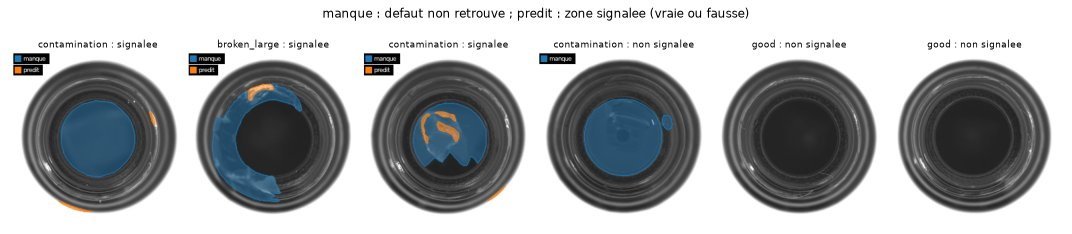

In [8]:
best = baselines["mvtec_bottle_reference"]  # le reglage retenu pour les bouteilles (et ses scores)
predictions = [segment(r, best["threshold"], best["min_area"]) for r in bottle_responses]  # masque predit par bouteille de test
# indices des images triees par aire de defaut decroissante (argsort trie en croissant, le signe - inverse l'ordre)
by_size = np.argsort([-int(m.sum()) for m in bottle_masks])  # int() : la somme d'un uint8 deborderait une fois negee
found = [int(i) for i in by_size if bottle_masks[i].any() and predictions[i].any()][:3]  # les 3 plus gros defauts retrouves
missed = [int(i) for i in by_size if bottle_masks[i].any() and not predictions[i].any()][:1]  # le plus gros defaut manque
good = [int(i) for i in np.flatnonzero([not m.any() for m in bottle_masks])][:2]  # 2 bouteilles saines (verite vide)
panels, titles = [], []  # images et titres de la galerie
for i in found + missed + good:  # pour chaque image choisie
    shown = resize_to(read_gray(bottle_test["path"].iloc[i]), BOTTLE_SIZE)  # l'image de test, en 256 x 256
    predicted = predictions[i]  # son masque predit
    # superpose un masque a 3 valeurs : 2 = zone predite, 1 = defaut vrai non predit (manque), 0 = rien
    panels.append(viz.overlay_mask(shown, np.where(predicted > 0, 2, bottle_masks[i]), class_names=["", "manque", "predit"]))
    titles.append(f"{bottle_test['defect_type'].iloc[i]} : {'signalee' if predicted.any() else 'non signalee'}")  # type et decision
# galerie sur une ligne, avec une legende generale (suptitle)
viz.grid(panels, titles, ncols=6, size=2.2, suptitle="manque : defaut non retrouve ; predit : zone signalee (vraie ou fausse)")

## 7. Resultats

Lecture :
- MVTec bottle : la comparaison a une reference detecte environ 60 % des bouteilles defectueuses
  SANS fausse alarme, sans aucun apprentissage. PatchCore (notebook 14) fait 100 % ; la
  localisation au pixel reste grossiere (Dice faible) car tout l'ecart de forme ressort.
- Magnetic Tile : la texture repond autant que les defauts ; le meilleur reglage au sens du Dice
  signale toutes les images. C'est la limite de la vision classique sur une surface naturelle,
  et le chiffre que le U-Net (notebook 12, Dice ~0,8) doit battre.

In [9]:
display(  # affiche le tableau final des resultats
    pd.DataFrame(  # tableau pandas : une colonne par jeu (retourne ensuite par .T)
        {  # dict construit par comprehension : nom du jeu -> ses resultats
            name: {  # pour un jeu : les lignes du tableau
                "methode": "carte de reponse (black-hat)" if name == "magnetic_tile" else "reference mediane + ECC",  # methode utilisee
                "seuil / aire choisis (val)": f"{m['threshold']} / {m['min_area']:.0f}",  # reglage choisi sur la validation
                "IoU": round(m["iou"], 3),  # IoU de test, arrondie a 3 decimales
                "Dice": round(m["dice"], 3),  # Dice de test
                "rappel image": round(m["recall"], 3),  # part des images a defaut signalees
                "fausses alarmes": round(m["false_alarm_rate"], 3),  # part des images saines signalees a tort
            }
            for name, m in baselines.items()  # pour chaque jeu (nom, metriques)
        }
    ).T  # .T : transpose, une ligne par jeu
)

,methode,seuil / aire choisis (val),IoU,Dice,rappel image,fausses alarmes
magnetic_tile,carte de reponse (black-hat),0.04 / 50,0.058,0.109,1.0,1.0
mvtec_bottle_reference,reference mediane + ECC,0.25 / 60,0.044,0.084,0.605,0.0


## 8. Passer en production

La recette `classical` fait la meme chose par configuration :

```yaml
data: {root: data/raw/magnetic_tile, layout: image_mask, extensions: [".jpg"], color: gray}
split: {file: outputs/classical/magnetic_tile/split.csv, strategy: stratified, val_fraction: 0.2, test_fraction: 0.3}
method: response
max_per_class: 60
preprocess:
  - {name: median_blur, ksize: 7}
  - {name: shading_division, sigma: 30, downscale: 2}
  - {name: blackhat, kernel: 21}
thresholds: [0.04, 0.06, 0.08, 0.1, 0.12, 0.16, 0.2]
min_areas: [50, 150, 400]
select: dice
```

```
python recipes/classical/scripts/baseline.py --config recipes/classical/configs/magnetic_tile.yaml
python recipes/classical/scripts/baseline.py --config recipes/classical/configs/mvtec_bottle_reference.yaml
python recipes/classical/scripts/measure_demo.py
```

Les operations (`median_blur`, `shading_division`, `blackhat`, `align_ecc`...) sont celles de
`vtb.preprocess` : la carte de reponse se met dans la carte d'un modele et se porte en C#
(chaque operation donne son equivalent OpenCvSharp).

Controle : la toolbox produit la meme carte de reponse et la meme difference a la reference que
le notebook ; si la recette a deja tourne, memes decoupages et memes chiffres.

In [10]:
import json  # json : lire les metriques ecrites par la recette (fichier texte structure)

from vtb.classical.compare import compare_to_reference  # comparaison a une reference, version toolbox
from vtb.preprocess import Pipeline  # chaine de pretraitements decrite par une liste de dicts (comme dans le YAML)

pipeline = Pipeline(  # la meme carte de reponse, decrite comme dans la configuration de la recette
    # median 7, puis correction d'eclairage (sigma 30, image reduite de moitie), puis black-hat 21
    [{"name": "median_blur", "ksize": 7}, {"name": "shading_division", "sigma": 30, "downscale": 2}, {"name": "blackhat", "kernel": 21}]
)
same_response = np.array_equal(pipeline(tile), response)  # vrai si la toolbox donne exactement la meme carte que le notebook
# difference calculee par la toolbox (seuil 1.0 et aire 0 : seule la carte "diff" nous interesse)
theirs = compare_to_reference(image, reference, align="ecc", blur_sigma=BLUR_SIGMA, threshold=1.0, min_area=0)["diff"]
same_diff = float(np.abs(theirs - diff).max())  # plus grand ecart entre les deux cartes de difference
print("carte de reponse identique a vtb.preprocess :", same_response)  # resultat du premier controle
print(f"difference a la reference : ecart max avec vtb.classical {same_diff:.2e}")  # :.2e = notation scientifique
for name, frame in (("magnetic_tile", tiles), ("mvtec_bottle_reference", bottles)):  # pour chaque jeu
    folder = Path("outputs/classical") / name  # dossier de sortie de la recette pour ce jeu
    if (folder / "split.csv").exists() and (folder / "metrics.json").exists():  # si la recette a deja tourne
        recipe_split = pd.read_csv(folder / "split.csv", keep_default_na=False)  # son decoupage ; "" reste "" (pas NaN)
        # meme split pour chaque chemin ? les deux tableaux sont indexes et tries par chemin avant comparaison
        same_split = recipe_split.set_index("path")["split"].sort_index().equals(frame.set_index("path")["split"].sort_index())
        recipe = json.loads((folder / "metrics.json").read_text())  # metriques de la recette
        gap = max(abs(recipe[k] - baselines[name][k]) for k in ("iou", "dice", "recall", "false_alarm_rate"))  # plus grand ecart
        print(f"{name} : decoupage identique a la recette : {same_split} | ecart max des metriques : {gap:.2e}")  # comparaison
    else:  # sinon, la recette n'a pas encore tourne
        print(f"{name} : lancer la recette pour comparer ({folder})")  # indique quoi lancer
assert same_response and same_diff < 1e-6  # arrete le notebook avec une erreur si le controle echoue

carte de reponse identique a vtb.preprocess : True
difference a la reference : ecart max avec vtb.classical 0.00e+00
magnetic_tile : decoupage identique a la recette : True | ecart max des metriques : 0.00e+00
mvtec_bottle_reference : decoupage identique a la recette : True | ecart max des metriques : 0.00e+00


## Pour aller plus loin

- Avant tout modele appris, faire tourner cette base sur ses donnees : si elle suffit, c'est la
  solution la plus simple a maintenir et a expliquer.
- Les operations OpenCV du notebook 02 (correction d'illumination, filtres orientes, FFT) donnent
  d'autres cartes de reponse ; le protocole de la section 6 les compare honnetement.
- Pour une mesure en production : calibrer avec un vrai damier (`vtb.classical.measure.calibrate_chessboard`)
  et verifier la repetabilite (meme piece mesuree 30 fois).